# Breast Cancer Diagnosis: Regression, Regularization & Gradient Descent

**Week 2 — Building on Week 1**

Last week we explored the Wisconsin Breast Cancer dataset through two lenses: a closed-form
linear solver and a gradient descent linear classifier, both implemented from scratch so we
could see exactly what was happening inside `model.fit()`.

This week we move to the way practitioners actually build models: **scikit-learn**. The
algorithms are the same ones from the lecture slides.
implementations. We keep the **same preprocessing** as before, then walk through four ideas.

**The journey:**

| Step | What we do | Why |
|---|---|---|
| **1. Preprocessing** | Re-run the Week 1 pipeline | Establish the clean data we will model |
| **2. Polynomial Regression** | `LinearRegression` + `PolynomialFeatures` | See overfitting, then tame it with L1 / L2 |
| **3. Logistic Regression** | `SGDClassifier` (log-loss) | Fit a classifier by gradient descent |
| **4. Gradient Descent Variants** | Batch, Stochastic| Compare how different optimisers learn |
| **Take-home** | Two guided exercises | Practice what you learned |

---

## Setup: Imports & Loading the Data

Same dataset as Week 1. We also import everything we need upfront so it is easy to see which
library each tool comes from.

In [3]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

# Models
from sklearn.linear_model import (
    LinearRegression
)
from sklearn.neural_network import MLPClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

In [4]:
df = pd.read_csv("/content/dataset.csv", index_col=0)
df = df.drop('id', axis=1)

print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (569, 31)


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 1: Preprocessing Pipeline (Week 1 Recap)

Same steps as Week 1, split, impute, scale, drop highly correlated features.

One change: labels are now **0 and 1** instead of -1 and 1. Scikit-learn's
`LogisticRegression` (and the binary cross entropy loss it minimises internally) expects this
convention.

In [5]:
# Labels: 1 = Malignant, 0 = Benign
X = df.drop('diagnosis', axis=1)
y = (df['diagnosis'] == 'M').astype(int).values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

numeric_cols = X.select_dtypes(include='number').columns

# Imputing Outliers
for col in numeric_cols: # Iterate through each numeric column

  Q1 = X_train[col].quantile(0.25) # Calculate the first quartile (25th percentile)
  Q3 = X_train[col].quantile(0.75) # Calculate the third quartile (75th percentile)
  IQR = Q3 - Q1 # Calculate the Interquartile Range (IQR)

  lower = Q1 - 1.5*IQR # Calculate the lower bound for outlier detection
  upper = Q3 + 1.5*IQR # Calculate the upper bound for outlier detection

  outlier_mask = (X_train[col] < lower) | (X_train[col] > upper) # Boolean mask: True where the value is an outlier
  num_outliers = outlier_mask.sum() # Count the number of outliers based on IQR

  if num_outliers > 0:
    median_val = X_train.loc[~outlier_mask, col].median() # Median computed from non-outlier values only, so the outliers themselves don't skew the value used to replace them
    X_train.loc[outlier_mask, col] = median_val # Replace each outlier with that column's median

    # apply the SAME train-fit bounds and value to test — no new stats from X_test
    test_outlier_mask = (X_test[col] < lower) | (X_test[col] > upper)
    X_test.loc[test_outlier_mask, col] = median_val


# Scale
scaler = StandardScaler()
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols]  = scaler.transform(X_test[numeric_cols])

# Drop highly correlated features (same threshold as Week 1: r > 0.9)
corr_matrix = X_train.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper.columns if any(upper[col] > 0.9)]
X_train = X_train.drop(columns=to_drop)
X_test  = X_test.drop(columns=to_drop)

print(f"Training set : {X_train.shape}")
print(f"Test set     : {X_test.shape}")
print(f"Dropped (high correlation): {to_drop}")

Training set : (455, 25)
Test set     : (114, 25)
Dropped (high correlation): ['perimeter_mean', 'area_mean', 'perimeter_se', 'radius_worst', 'perimeter_worst']


### Evaluation Helper

We will call this for every model variant, so let us define it once.

In [6]:
results = {}   # we will fill this as we go

def evaluate(model_name, y_true, y_pred):

    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec  = recall_score(y_true, y_pred)
    f1   = f1_score(y_true, y_pred)

    print(f"  {model_name}")
    print(f"  Accuracy  : {acc*100:.1f}%")
    print(f"  Precision : {prec:.3f}")
    print(f"  Recall    : {rec:.3f}")
    print(f"  F1 Score  : {f1:.3f}")

    cm   = confusion_matrix(y_true, y_pred, labels=[1, 0])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                   display_labels=['Malignant', 'Benign'])
    disp.plot(colorbar=False)
    plt.title(f'Confusion Matrix — {model_name}')
    plt.tight_layout()
    plt.show()

    results[model_name] = {
        'accuracy': acc, 'precision': prec, 'recall': rec, 'f1': f1
    }

---

## 2: Polynomial Regression

### A quick experiment before we classify

Our real goal is to *classify* tumours, but first we run a small experiment with plain
**linear regression**. We treat the label as a number (1 = Malignant, 0 = Benign) and ask linear
regression to predict it. This is not how we would ship a diagnosis model, but it is the
cleanest way to *see* three very important ideas:

1. **Polynomial features** let a linear model bend, `PolynomialFeatures` adds squared terms
   (x₁²) and interaction terms (x₁·x₂).
2. **Overfitting**, a model that is too flexible memorises the training data and fails on new data.
3. **Regularization (L1 and L2)**, a penalty that keeps the weights small and the model honest.

We measure quality with Accuracy score :

>  Accuracy close to **100** = predictions match the targets.
> Accuracy score that is high on training data but **much lower on test data** = the model overfit.

### 2.1 Watching a model overfit

We try three levels of flexibility on the **same** data:

- **degree 1** — the plain linear model (25 features).
- **degree 2** — adds squares and pairwise products (25 → 350 features).
- **degree 3** — even more terms (25 → 3275 features), far more features than we have rows (455).

Watch the training Accuracy score climb toward 1.0 while the test Accuracy score falls apart. That gap *is* overfitting.

In [7]:

degrees = [1, 2, 3]

train_accuracy_scores = []
test_accuracy_scores = []

print(f"{'Degree':>6} | {'# Features':>10} | {'Train Accuracy':>9} | {'Test Accuracy':>9}")
print("-" * 45)

for degree in degrees:
    poly = PolynomialFeatures(degree=degree, include_bias=False)

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    # Continuous predictions
    train_pred_prob = model.predict(X_train_poly)
    test_pred_prob = model.predict(X_test_poly)

    # Apply threshold
    train_pred = (train_pred_prob >= 0.5).astype(int)
    test_pred = (test_pred_prob >= 0.5).astype(int)

    train_accuracy = accuracy_score(y_train, train_pred)*100
    test_accuracy = accuracy_score(y_test, test_pred)*100

    train_accuracy_scores.append(train_accuracy)
    test_accuracy_scores.append(test_accuracy)

    print(
        f"{degree:>6} | {X_train_poly.shape[1]:>10} | "
        f"{train_accuracy:>9.1f}% | {test_accuracy:>9.1f}%"
    )

Degree | # Features | Train Accuracy | Test Accuracy
---------------------------------------------
     1 |         25 |      95.8% |      98.2%
     2 |        350 |     100.0% |      74.6%
     3 |       3275 |     100.0% |      75.4%


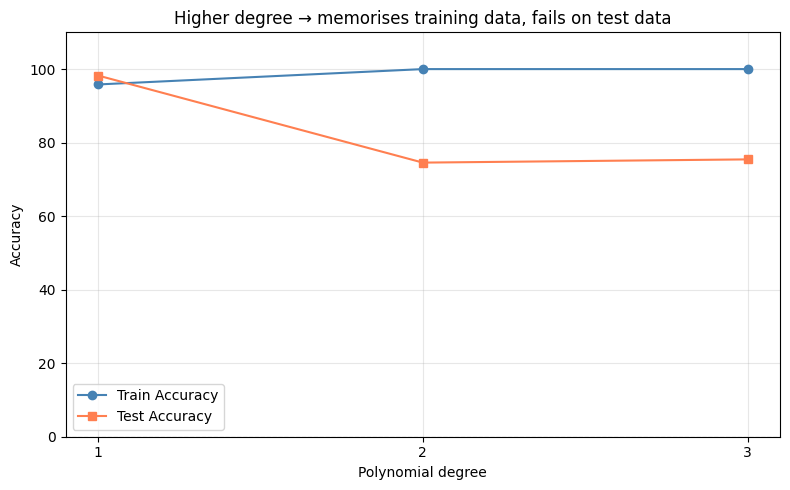

In [8]:
# The same story as a picture
plt.figure(figsize=(8, 5))
plt.plot(degrees, train_accuracy_scores, 'o-', color='steelblue', label='Train Accuracy')
plt.plot(degrees, test_accuracy_scores,  's-', color='coral',     label='Test Accuracy')
plt.axhline(0, color='gray', linewidth=0.8, linestyle='--')
plt.ylim(0, 110)
plt.xticks(degrees)
plt.xlabel('Polynomial degree')
plt.ylabel('Accuracy')
plt.title('Higher degree → memorises training data, fails on test data')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()